# Trial 7 — Modality Ablation Ladder (Volume & Volatility)

**The question:** Trials 2-6 hit a ~73% directional-accuracy / ~0.069 MSE ceiling on
return-only data. The ablation showed this is ~66% mean-reversion + ~7% learned
structure — i.e. return correlations are near their information ceiling. Volume and
volatility correlations are *independent* signals (verified cross-corr 0.12 / 0.18).
**Do they carry predictive signal that breaks the wall?**

**Design — ablation ladder.** Same ConvLSTM (Trial 5/6 winner), same 4-term loss,
same cosine schedule, trained on 4 channel configurations:

| Rung | Modalities | Tests |
|------|-----------|-------|
| 1 | return | baseline (should ~reproduce Trial 5 ConvLSTM = sanity check) |
| 2 | return + volume | does volume help? |
| 3 | return + volatility | does volatility help? |
| 4 | return + volume + volatility | combined |

Each modality is expanded with Trial 5's 5 sub-channels (raw, d1, d5, roll_mean,
roll_std), so every modality is treated identically. **Target is always the
return-correlation matrix 5 steps ahead.**

If no rung beats the baseline, that is itself a publishable finding: the ceiling is
fundamental even with richer input modalities.

Output prefix `trial7_`. No files deleted.

In [1]:
# Cell 1 - Imports & Configuration
import os, time, pickle, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings('ignore')

_cwd        = os.getcwd()
PROJECT_DIR = os.path.abspath(os.path.join(_cwd, '..')) \
              if os.path.basename(_cwd) == 'notebooks' else _cwd
DATA_DIR    = os.path.join(PROJECT_DIR, 'data', 'processed')
MODELS_DIR  = os.path.join(PROJECT_DIR, 'models')
PREDS_DIR   = os.path.join(PROJECT_DIR, 'outputs', 'predictions')
PLOTS_DIR   = os.path.join(PROJECT_DIR, 'outputs', 'plots')

N_STOCKS    = 95
LOOKBACK    = 20
HORIZON     = 5
TRAIN_RATIO = 0.70

SUBCH         = 5      # sub-channels per modality (raw, d1, d5, roll_mean, roll_std)
DELTA_SHORT   = 1
DELTA_LONG    = 5
ROLLING_WIN   = 4

BATCH_SIZE   = 16
LR           = 1e-3
MAX_EPOCHS   = 60
WEIGHT_DECAY = 1e-4
T_0, T_MULT, ETA_MIN = 20, 2, 1e-6
PATIENCE     = 15

ALPHA, BETA, GAMMA, DELTA = 0.35, 0.25, 0.30, 0.10
DIR_MAG_THRESH = 0.005

device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PIN_MEM = device.type == 'cuda'

# Ablation ladder: each config is a list of modality keys
ABLATION_CONFIGS = [
    ('return',            ['return']),
    ('return+volume',     ['return', 'volume']),
    ('return+volat',      ['return', 'volat']),
    ('return+vol+volat',  ['return', 'volume', 'volat']),
]

print(f'Device   : {device}')
print(f'PyTorch  : {torch.__version__}')
print(f'Sub-ch/modality: {SUBCH}')
print('Ablation ladder:')
for name, mods in ABLATION_CONFIGS:
    print(f'  {name:<18} -> {len(mods)*SUBCH} channels  ({mods})')


Device   : cuda
PyTorch  : 2.6.0+cu124
Sub-ch/modality: 5
Ablation ladder:
  return             -> 5 channels  (['return'])
  return+volume      -> 10 channels  (['return', 'volume'])
  return+volat       -> 10 channels  (['return', 'volat'])
  return+vol+volat   -> 15 channels  (['return', 'volume', 'volat'])


In [2]:
# Cell 2 - Load the three modality videos (all aligned, same Fiedler layout)
corr_video = np.load(os.path.join(DATA_DIR, 'corr_video.npy'))          # return
vol_video  = np.load(os.path.join(DATA_DIR, 'volume_corr_video.npy'))   # volume
vlt_video  = np.load(os.path.join(DATA_DIR, 'volat_corr_video.npy'))    # volatility
with open(os.path.join(DATA_DIR, 'video_meta.pkl'), 'rb') as f:
    vm = pickle.load(f)

MODALITY_VIDEOS = {'return': corr_video, 'volume': vol_video, 'volat': vlt_video}
N_SNAPS = corr_video.shape[0]
for k, v in MODALITY_VIDEOS.items():
    print(f'{k:<8}: {v.shape}  mean={v.mean():+.3f}  range=[{v.min():+.3f},{v.max():+.3f}]')
print(f'N_SNAPS = {N_SNAPS}')


return  : (1157, 95, 95)  mean=+0.224  range=[-0.989,+1.000]
volume  : (1157, 95, 95)  mean=+0.097  range=[-0.761,+1.000]
volat   : (1157, 95, 95)  mean=+0.316  range=[-0.872,+1.000]
N_SNAPS = 1157


In [3]:
# Cell 3 - Build 5 sub-channels per modality (Trial 5 scheme)

def build_subchannels(video, delta_short=1, delta_long=5, win=4):
    T, H, W = video.shape
    out = np.zeros((T, 5, H, W), dtype=np.float32)
    out[:, 0] = video
    out[delta_short:, 1] = video[delta_short:] - video[:-delta_short]
    out[delta_long:,  2] = video[delta_long:]  - video[:-delta_long]
    cum, cum2 = np.cumsum(video, 0), np.cumsum(video**2, 0)
    for t in range(T):
        lo = max(0, t - win + 1); n = t - lo + 1
        s  = cum[t]  - (cum[lo-1]  if lo > 0 else 0.0)
        s2 = cum2[t] - (cum2[lo-1] if lo > 0 else 0.0)
        mean = s / n; var = np.maximum(0.0, s2 / n - mean**2)
        out[t, 3] = mean; out[t, 4] = np.sqrt(var)
    return out

MODALITY_SUBCH = {k: build_subchannels(v, DELTA_SHORT, DELTA_LONG, ROLLING_WIN)
                  for k, v in MODALITY_VIDEOS.items()}
for k, v in MODALITY_SUBCH.items():
    print(f'{k:<8}: subchannels {v.shape}  ~{v.nbytes/1e6:.0f} MB')


return  : subchannels (1157, 5, 95, 95)  ~209 MB
volume  : subchannels (1157, 5, 95, 95)  ~209 MB
volat   : subchannels (1157, 5, 95, 95)  ~209 MB


In [4]:
# Cell 4 - Split, baselines, channel-configurable dataset

n_valid   = N_SNAPS - HORIZON
frame_mse = np.array([float(np.mean((corr_video[t] - corr_video[t+HORIZON])**2))
                      for t in range(n_valid)], dtype=np.float32)
vol_thresh = float(np.median(frame_mse))
valid_snaps = np.array([s for s in range(n_valid) if s >= LOOKBACK])
sv = frame_mse[valid_snaps]
volatile = valid_snaps[sv >= vol_thresh]; stable = valid_snaps[sv < vol_thresh]
np.random.seed(42)
vtr = np.random.choice(volatile, int(len(volatile)*TRAIN_RATIO), replace=False)
vva = np.setdiff1d(volatile, vtr)
str_ = np.random.choice(stable, int(len(stable)*TRAIN_RATIO), replace=False)
sva = np.setdiff1d(stable, str_)
train_snaps = np.sort(np.concatenate([vtr, str_]))
val_snaps   = np.sort(np.concatenate([vva, sva]))

persistence_mse = float(np.mean([np.mean((corr_video[s]-corr_video[s+HORIZON])**2) for s in val_snaps]))
mean_train_frame= corr_video[train_snaps].mean(axis=0)
mean_frame_mse  = float(np.mean([np.mean((mean_train_frame-corr_video[s+HORIZON])**2) for s in val_snaps]))
val_currents    = corr_video[val_snaps - 1].astype(np.float32)
val_futures     = corr_video[val_snaps + HORIZON].astype(np.float32)
print(f'Train {len(train_snaps)} | Val {len(val_snaps)} | persist {persistence_mse:.5f} | mean-frame {mean_frame_mse:.5f}')

class MultiModalDataset(Dataset):
    """Stacks the SUBCH sub-channels of each selected modality along channel axis."""
    def __init__(self, snaps, modalities):
        self.snaps = snaps
        self.mods  = modalities
    def __len__(self): return len(self.snaps)
    def __getitem__(self, idx):
        s = self.snaps[idx]
        # (L, SUBCH*n_mod, H, W)
        frames = np.concatenate(
            [MODALITY_SUBCH[m][s-LOOKBACK:s] for m in self.mods], axis=1
        ).astype(np.float32)
        future  = corr_video[s + HORIZON].astype(np.float32)
        current = corr_video[s - 1].astype(np.float32)
        weight  = float(frame_mse[s])
        return (torch.from_numpy(frames), torch.from_numpy(future),
                torch.from_numpy(current), torch.tensor(weight, dtype=torch.float32))

def make_loaders(modalities):
    tr = MultiModalDataset(train_snaps, modalities)
    va = MultiModalDataset(val_snaps,   modalities)
    return (DataLoader(tr, batch_size=BATCH_SIZE, shuffle=True,  pin_memory=PIN_MEM),
            DataLoader(va, batch_size=BATCH_SIZE, shuffle=False, pin_memory=PIN_MEM))
print('Dataset ready.')


Train 792 | Val 340 | persist 0.12814 | mean-frame 0.07130
Dataset ready.


In [5]:
# Cell 5 - Loss + ConvLSTM (channel-count configurable)

def combined_loss(pred, target, current, weights,
                  alpha=ALPHA, beta=BETA, gamma=GAMMA, delta=DELTA, dir_thresh=DIR_MAG_THRESH):
    per_sample = ((pred - target)**2).mean(dim=(1,2))
    w = weights / weights.sum() * len(weights)
    mse_loss = (w * per_sample).mean()
    pf, tf = pred.flatten(1), target.flatten(1)
    pc = pf - pf.mean(1, keepdim=True); tc = tf - tf.mean(1, keepdim=True)
    pear = (pc*tc).sum(1) / (pc.norm(dim=1)*tc.norm(dim=1) + 1e-8)
    pear_loss = (1 - pear).mean()
    pd_, td_ = pred - current, target - current
    mask = (td_.abs() > dir_thresh).float()
    dir_loss = (F.relu(-(pd_*td_)) * mask).sum() / mask.sum().clamp(min=1.0)
    traj_loss = (pd_.abs() - td_.abs()).pow(2).mean()
    return alpha*mse_loss + beta*pear_loss + gamma*dir_loss + delta*traj_loss

class ConvLSTMCell(nn.Module):
    def __init__(self, in_ch, hid_ch, k=3):
        super().__init__()
        self.hid_ch = hid_ch
        self.conv = nn.Conv2d(in_ch + hid_ch, 4*hid_ch, k, padding=k//2)
    def forward(self, x, h, c):
        i,f,g,o = self.conv(torch.cat([x,h],1)).chunk(4,1)
        c = torch.sigmoid(f)*c + torch.sigmoid(i)*torch.tanh(g)
        h = torch.sigmoid(o)*torch.tanh(c)
        return h, c
    def init_hidden(self, B, sp, dev):
        z = torch.zeros(B, self.hid_ch, sp, sp, device=dev); return z, z.clone()

class ConvLSTMReg(nn.Module):
    def __init__(self, n_channels, n_stocks=N_STOCKS, sp=24, hid_ch=32, dropout=0.3):
        super().__init__()
        self.n, self.sp, self.hid_ch = n_stocks, sp, hid_ch
        self.down = nn.Sequential(
            nn.Conv2d(n_channels, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.AdaptiveAvgPool2d((sp, sp)), nn.Conv2d(32, hid_ch, 1))
        self.cell1 = ConvLSTMCell(hid_ch, hid_ch)
        self.cell2 = ConvLSTMCell(hid_ch, hid_ch)
        self.lnorm = nn.LayerNorm([hid_ch, sp, sp])
        self.drop2d = nn.Dropout2d(dropout)
        flat = hid_ch*sp*sp
        self.decoder = nn.Sequential(
            nn.Flatten(), nn.Linear(flat, 1024), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(1024, 2048), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(2048, n_stocks*n_stocks), nn.Tanh())
    def forward(self, frames):
        B,L,C,H,W = frames.shape
        enc = self.down(frames.reshape(B*L,C,H,W)).reshape(B,L,self.hid_ch,self.sp,self.sp)
        h1,c1 = self.cell1.init_hidden(B,self.sp,frames.device)
        h2,c2 = self.cell2.init_hidden(B,self.sp,frames.device)
        for t in range(L):
            h1,c1 = self.cell1(enc[:,t],h1,c1); h1 = self.drop2d(h1)
            h2,c2 = self.cell2(h1,h2,c2)
        return self.decoder(self.lnorm(h2)).reshape(B,self.n,self.n)
print('Loss + ConvLSTM ready.')


Loss + ConvLSTM ready.


In [6]:
# Cell 6 - Training utilities

def run_epoch(model, loader, opt, is_train, desc=''):
    model.train() if is_train else model.eval()
    tot_loss = tot_n = 0; preds, futs = [], []
    ctx = torch.enable_grad() if is_train else torch.no_grad()
    with ctx:
        for frames, future, current, w in tqdm(loader, desc=desc, ncols=90, leave=False):
            frames, future = frames.to(device), future.to(device)
            current, w = current.to(device), w.to(device)
            pred = model(frames)
            loss = combined_loss(pred, future, current, w)
            if is_train:
                opt.zero_grad(); loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tot_loss += loss.item()*frames.size(0); tot_n += frames.size(0)
            preds.append(pred.detach().cpu().numpy()); futs.append(future.cpu().numpy())
    return tot_loss/tot_n, np.concatenate(preds), np.concatenate(futs)

def compute_metrics(preds, futures, currents=None):
    mse = float(np.mean((preds-futures)**2))
    r,_ = pearsonr(preds.reshape(-1)[:500000], futures.reshape(-1)[:500000])
    vp = (persistence_mse-mse)/persistence_mse*100
    vm = (mean_frame_mse-mse)/mean_frame_mse*100
    da = float(np.mean(np.sign(preds-currents)==np.sign(futures-currents))) if currents is not None else None
    return dict(mse=mse, pearson_r=r, dir_acc=da, vs_persist=vp, vs_mean=vm)

def train_config(name, modalities):
    t_dl, v_dl = make_loaders(modalities)
    n_ch = len(modalities) * SUBCH
    model = ConvLSTMReg(n_channels=n_ch).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(opt, T_0=T_0, T_mult=T_MULT, eta_min=ETA_MIN)
    best_mse, patience, best_preds, hist = float('inf'), 0, None, []
    save_path = os.path.join(MODELS_DIR, f'trial7_{name}_best.pt')
    print(f'\n{"="*64}\nConfig: {name}  ({n_ch} channels)\n{"="*64}')
    for epoch in range(1, MAX_EPOCHS+1):
        t0 = time.time()
        tr, _, _ = run_epoch(model, t_dl, opt, True,  f'Ep{epoch:>2} Tr')
        _, vp, vf = run_epoch(model, v_dl, opt, False, f'Ep{epoch:>2} Va')
        sched.step()
        m = compute_metrics(vp, vf, val_currents)
        star = ' *' if m['mse'] < best_mse else ''
        hist.append(dict(epoch=epoch, va_mse=m['mse'], pearson_r=m['pearson_r'], dir_acc=m['dir_acc']))
        print(f"Ep{epoch:>2}/{MAX_EPOCHS} | tr={tr:.5f} | va={m['mse']:.5f} | r={m['pearson_r']:.4f} | "
              f"dir={m['dir_acc']:.3f} | vs_mean={m['vs_mean']:+.1f}% | {time.time()-t0:.0f}s{star}")
        if m['mse'] < best_mse:
            best_mse, patience, best_preds = m['mse'], 0, vp.copy()
            torch.save(model.state_dict(), save_path)
        else:
            patience += 1
            if patience >= PATIENCE:
                print(f'Early stop ep{epoch}, best={best_mse:.6f}'); break
    np.save(os.path.join(PREDS_DIR, f'trial7_{name}_val_preds.npy'), best_preds)
    return hist, best_preds
print('Training utilities ready.')


Training utilities ready.


In [7]:
# Cell 7 - Run the full ablation ladder
results = {}
histories = {}
for name, mods in ABLATION_CONFIGS:
    hist, preds = train_config(name, mods)
    histories[name] = hist
    results[name] = compute_metrics(preds, val_futures, val_currents)
print('\nAblation ladder complete.')



Config: return  (5 channels)


Ep 1/60 | tr=0.22198 | va=0.07866 | r=0.2853 | dir=0.707 | vs_mean=-10.3% | 11s *


Ep 2/60 | tr=0.18964 | va=0.07341 | r=0.3094 | dir=0.719 | vs_mean=-3.0% | 11s *


Ep 3/60 | tr=0.18787 | va=0.07756 | r=0.3108 | dir=0.708 | vs_mean=-8.8% | 10s


Ep 4/60 | tr=0.18788 | va=0.07948 | r=0.3057 | dir=0.703 | vs_mean=-11.5% | 10s


...

Ep31/60 | tr=0.17882 | va=0.07183 | r=0.3556 | dir=0.722 | vs_mean=-0.7% | 18s


Ep32/60 | tr=0.17751 | va=0.07186 | r=0.3567 | dir=0.722 | vs_mean=-0.8% | 17s


Ep33/60 | tr=0.17856 | va=0.07174 | r=0.3642 | dir=0.723 | vs_mean=-0.6% | 17s


Ep34/60 | tr=0.17725 | va=0.07172 | r=0.3659 | dir=0.722 | vs_mean=-0.6% | 18s


Ep35/60 | tr=0.17651 | va=0.07229 | r=0.3753 | dir=0.721 | vs_mean=-1.4% | 18s
Early stop ep35, best=0.069919

Ablation ladder complete.


Config                  Val MSE  Pearson r   Dir Acc   vs Mean
--------------------------------------------------------------
return                 0.068991     0.3622     0.729     +3.2%
return+volume          0.069661     0.3600     0.729     +2.3%
return+volat           0.072092     0.2930     0.723     -1.1%
return+vol+volat       0.069919     0.3745     0.728     +1.9%
--------------------------------------------------------------
T5 ConvLSTM (ref)      0.068600     0.3724     0.730
persistence            0.128137        n/a     0.500
mean-frame             0.071299        n/a       n/a

Contribution vs return-only baseline:
  return+volume        dMSE=+0.000669  dDir=-0.03pp  dPearson=-0.0022
  return+volat         dMSE=+0.003101  dDir=-0.58pp  dPearson=-0.0692
  return+vol+volat     dMSE=+0.000928  dDir=-0.16pp  dPearson=+0.0123


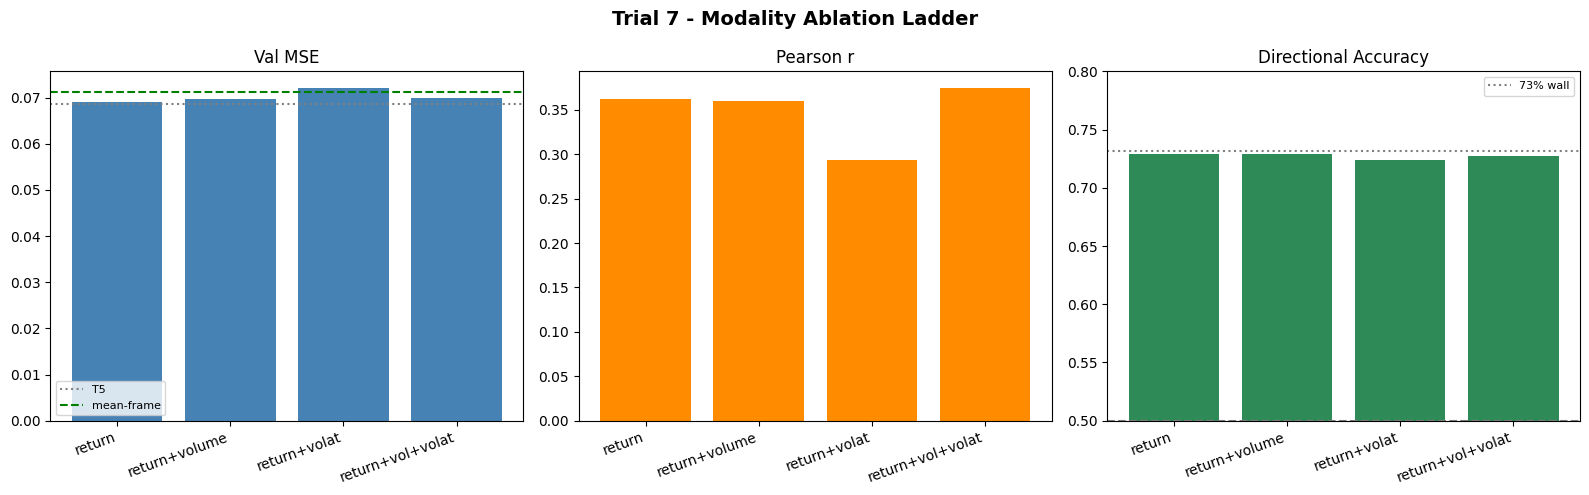


Saved trial7_ablation.png


In [8]:
# Cell 8 - Results table & comparison

T5_BASELINE = dict(mse=0.068600, pearson_r=0.3724, dir_acc=0.730)  # Trial 5 ConvLSTM

print(f'{"Config":<20} {"Val MSE":>10} {"Pearson r":>10} {"Dir Acc":>9} {"vs Mean":>9}')
print('-'*62)
for name, _ in ABLATION_CONFIGS:
    m = results[name]
    print(f"{name:<20} {m['mse']:>10.6f} {m['pearson_r']:>10.4f} {m['dir_acc']:>9.3f} {m['vs_mean']:>+8.1f}%")
print('-'*62)
print(f"{'T5 ConvLSTM (ref)':<20} {T5_BASELINE['mse']:>10.6f} {T5_BASELINE['pearson_r']:>10.4f} {T5_BASELINE['dir_acc']:>9.3f}")
print(f"{'persistence':<20} {persistence_mse:>10.6f} {'n/a':>10} {0.5:>9.3f}")
print(f"{'mean-frame':<20} {mean_frame_mse:>10.6f} {'n/a':>10} {'n/a':>9}")

# Deltas vs the return-only rung (isolates each modality's contribution)
base = results['return']
print('\nContribution vs return-only baseline:')
for name, _ in ABLATION_CONFIGS[1:]:
    m = results[name]
    print(f"  {name:<20} dMSE={m['mse']-base['mse']:+.6f}  dDir={(m['dir_acc']-base['dir_acc'])*100:+.2f}pp  dPearson={m['pearson_r']-base['pearson_r']:+.4f}")

# Plot
names = [n for n,_ in ABLATION_CONFIGS]
mses  = [results[n]['mse'] for n in names]
dirs  = [results[n]['dir_acc'] for n in names]
pears = [results[n]['pearson_r'] for n in names]
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Trial 7 - Modality Ablation Ladder', fontsize=14, fontweight='bold')
x = np.arange(len(names))
ax[0].bar(x, mses, color='steelblue'); ax[0].axhline(T5_BASELINE['mse'], color='gray', ls=':', label='T5')
ax[0].axhline(mean_frame_mse, color='green', ls='--', label='mean-frame')
ax[0].set_xticks(x); ax[0].set_xticklabels(names, rotation=20, ha='right'); ax[0].set_title('Val MSE'); ax[0].legend(fontsize=8)
ax[1].bar(x, pears, color='darkorange'); ax[1].set_xticks(x); ax[1].set_xticklabels(names, rotation=20, ha='right'); ax[1].set_title('Pearson r')
ax[2].bar(x, dirs, color='seagreen'); ax[2].axhline(0.5, color='grey', ls='--'); ax[2].axhline(0.732, color='gray', ls=':', label='73% wall')
ax[2].set_xticks(x); ax[2].set_xticklabels(names, rotation=20, ha='right'); ax[2].set_ylim(0.5, 0.8); ax[2].set_title('Directional Accuracy'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(PLOTS_DIR, 'trial7_ablation.png'), dpi=150, bbox_inches='tight'); plt.show()
print('\nSaved trial7_ablation.png')
